<a href="https://colab.research.google.com/github/aswithapatel-0518/ML_LABPROGRAMS/blob/main/mlex_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIMENT 11
DATA LEAKAGE, CROSS-VALIDATION AND NESTED CV

Please upload your CSV dataset.


Saving placement_predict_50k Dataset.csv to placement_predict_50k Dataset (1).csv

File selected: placement_predict_50k Dataset (1).csv

Dataset loaded successfully!

Dataset shape:
(50000, 32)

First 5 rows:
   StudentID  Gender       City CollegeTier Stream Specialisation Hostel  \
0          1    Male  Ahmedabad       Tier2    ECE     Networking     No   
1          2  Female     Mumbai       Tier2    ECE    DataScience    Yes   
2          3    Male    Kolkata       Tier2     IT    DataScience    Yes   
3          4    Male     Jaipur       Tier1     CS             AI     No   
4          5    Male       Pune       Tier2     IT    DataScience    Yes   

  HistoryOfBacklogs  SGPA_Sem1  SGPA_Sem2  ...  Publications  \
0                No       6.02       6.54  ...             0   
1               Yes       5.84       5.12  ...             0   
2                No       4.91       5.29  ...             0   
3                No       7.67       8.03  ...             0   
4             

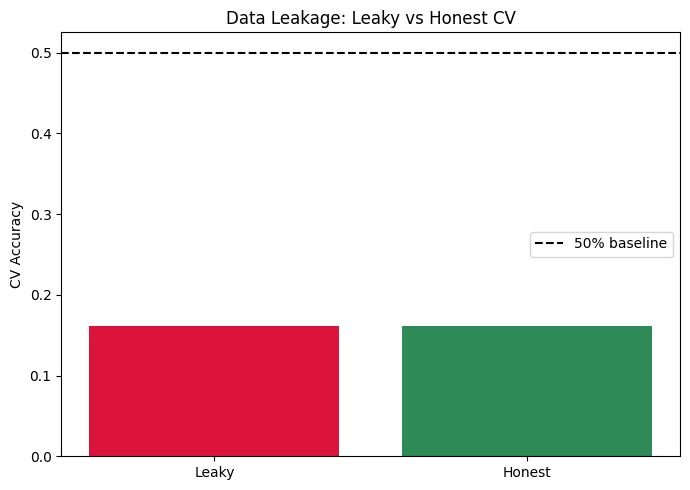



B. K-FOLD VS STRATIFIED K-FOLD

KFold:
Mean accuracy = 0.1598
Std deviation = 0.0023

StratifiedKFold:
Mean accuracy = 0.1602
Std deviation = 0.0016

Stratified K-Fold class ratios:
Fold 1: {0: 703, 1: 1013, 2: 812, 3: 674, 4: 999, 5: 1623, 6: 977, 7: 1192, 8: 1413, 9: 594}
Fold 2: {0: 703, 1: 1013, 2: 811, 3: 675, 4: 999, 5: 1623, 6: 976, 7: 1193, 8: 1413, 9: 594}
Fold 3: {0: 703, 1: 1012, 2: 812, 3: 674, 4: 1000, 5: 1622, 6: 977, 7: 1192, 8: 1414, 9: 594}
Fold 4: {0: 703, 1: 1012, 2: 812, 3: 674, 4: 999, 5: 1623, 6: 977, 7: 1192, 8: 1414, 9: 594}
Fold 5: {0: 703, 1: 1012, 2: 812, 3: 674, 4: 999, 5: 1623, 6: 977, 7: 1192, 8: 1414, 9: 594}


C. NESTED CROSS-VALIDATION

Inner CV folds: 4


In [ ]:
# ============================================================
# EXPERIMENT 8
# DATA LEAKAGE, CROSS-VALIDATION AND NESTED CV
#
# Universal Google Colab Version
# Works with different CSV classification datasets
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import (
    cross_val_score,
    KFold,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


# ============================================================
# 1. UPLOAD CSV FILE
# ============================================================

print("=" * 70)
print("EXPERIMENT 11")
print("DATA LEAKAGE, CROSS-VALIDATION AND NESTED CV")
print("=" * 70)

print("\nPlease upload your CSV dataset.")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("No file was uploaded.")

file_path = list(uploaded.keys())[0]

print("\nFile selected:", file_path)


# ============================================================
# 2. LOAD DATASET
# ============================================================

try:
    df = pd.read_csv(file_path)
except Exception as e:
    raise ValueError(f"Could not read CSV file: {e}")


print("\nDataset loaded successfully!")

print("\nDataset shape:")
print(df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())


# ============================================================
# 3. BASIC CLEANING
# ============================================================

# Remove completely empty columns
empty_columns = df.columns[
    df.isna().all()
].tolist()

if empty_columns:

    print("\nRemoving completely empty columns:")
    print(empty_columns)

    df = df.drop(columns=empty_columns)


# Remove completely duplicate rows
duplicate_count = df.duplicated().sum()

if duplicate_count > 0:

    print(
        f"\nRemoving {duplicate_count} duplicate rows."
    )

    df = df.drop_duplicates()


print("\nShape after basic cleaning:")
print(df.shape)


# ============================================================
# 4. AUTOMATIC TARGET DETECTION
# ============================================================

possible_targets = [
    "target",
    "label",
    "class",
    "y",
    "placed",
    "placement",
    "fraud",
    "is_fraud",
    "churn",
    "outcome",
    "status",
    "default",
    "diagnosis",
    "species",
    "result",
    "prediction",
    "category",
    "type"
]


target_col = None


# ------------------------------------------------------------
# First: look for standard target names
# ------------------------------------------------------------

for col in df.columns:

    clean_name = (
        str(col)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    if clean_name in possible_targets:

        target_col = col
        break


# ============================================================
# 5. IF TARGET IS NOT FOUND, FIND POSSIBLE TARGET COLUMNS
# ============================================================

if target_col is None:

    print("\nNo standard target column name was found.")

    print("\nPossible target columns:")

    candidates = []

    for col in df.columns:

        unique_count = df[col].nunique(
            dropna=True
        )

        # Classification target usually has relatively
        # few unique classes
        if unique_count >= 2 and unique_count <= 20:

            candidates.append(
                (col, unique_count)
            )

    if candidates:

        for col, count in candidates:

            print(
                f"  {col} "
                f"-> {count} unique values"
            )

    else:

        print(
            "No obvious classification target "
            "was detected."
        )


    # --------------------------------------------------------
    # Ask user to select target
    # --------------------------------------------------------

    print("\nAll columns:")

    for i, col in enumerate(df.columns):

        print(
            f"{i}: {col} "
            f"({df[col].nunique(dropna=True)} unique values)"
        )


    target_input = input(
        "\nEnter the TARGET column name "
        "(or column number): "
    ).strip()


    # Allow column number
    if target_input.isdigit():

        index = int(target_input)

        if index < 0 or index >= len(df.columns):

            raise ValueError(
                "Invalid column number."
            )

        target_col = df.columns[index]

    else:

        # Find exact column name
        matching = [
            col for col in df.columns
            if str(col).strip() == target_input
        ]

        if not matching:

            raise ValueError(
                f"Column '{target_input}' "
                "was not found."
            )

        target_col = matching[0]


print("\n" + "=" * 70)
print("TARGET INFORMATION")
print("=" * 70)

print(
    "Target column:",
    target_col
)


# ============================================================
# 6. REMOVE ROWS WITH MISSING TARGET
# ============================================================

missing_target = df[target_col].isna().sum()

if missing_target > 0:

    print(
        f"\nRemoving {missing_target} rows "
        "with missing target values."
    )

    df = df.dropna(
        subset=[target_col]
    )


# ============================================================
# 7. TARGET DISTRIBUTION
# ============================================================

print("\nTarget distribution:")

target_counts = df[target_col].value_counts()

print(target_counts)


print(
    "\nNumber of target classes:",
    len(target_counts)
)


# ============================================================
# 8. VERIFY CLASSIFICATION DATASET
# ============================================================

if len(target_counts) < 2:

    raise ValueError(
        "\nERROR: Target has fewer than 2 classes.\n"
        "This experiment requires a classification dataset."
    )


# Number of samples in smallest class
min_class_count = target_counts.min()

print(
    "\nSmallest class contains:",
    min_class_count,
    "samples"
)


# Need at least 2 samples per class for Stratified CV
if min_class_count < 2:

    raise ValueError(
        "\nERROR: One target class contains only "
        f"{min_class_count} sample.\n\n"
        "Cross-validation cannot be performed reliably "
        "with this target column.\n\n"
        "Please choose the correct classification target."
    )


# ============================================================
# 9. AUTOMATIC NUMBER OF CV FOLDS
# ============================================================

# Maximum possible stratified folds is the size
# of the smallest class.

N_SPLITS = min(
    5,
    int(min_class_count)
)

print(
    "\nNumber of CV folds selected:",
    N_SPLITS
)


# ============================================================
# 10. SEPARATE FEATURES AND TARGET
# ============================================================

X_df = df.drop(
    columns=[target_col]
)

y = df[target_col]


# ============================================================
# 11. REMOVE ID-LIKE COLUMNS
# ============================================================

id_columns = []

for col in X_df.columns:

    name = (
        str(col)
        .strip()
        .lower()
        .replace(" ", "_")
    )

    unique_count = X_df[col].nunique(
        dropna=True
    )

    # Common ID names
    if (
        name == "id"
        or name.endswith("_id")
        or name.startswith("id_")
        or name in [
            "studentid",
            "student_id",
            "customerid",
            "customer_id",
            "transactionid",
            "transaction_id"
        ]
    ):

        id_columns.append(col)


if id_columns:

    print("\nRemoving ID-like columns:")

    for col in id_columns:
        print(" -", col)

    X_df = X_df.drop(
        columns=id_columns
    )


# ============================================================
# 12. REMOVE CONSTANT COLUMNS
# ============================================================

constant_columns = []

for col in X_df.columns:

    if X_df[col].nunique(
        dropna=True
    ) <= 1:

        constant_columns.append(col)


if constant_columns:

    print(
        "\nRemoving constant columns:"
    )

    for col in constant_columns:
        print(" -", col)

    X_df = X_df.drop(
        columns=constant_columns
    )


# ============================================================
# 13. DETECT NUMERIC FEATURES
# ============================================================

numeric_features = X_df.select_dtypes(
    include=[
        "int64",
        "int32",
        "int16",
        "float64",
        "float32",
        "float16"
    ]
).columns.tolist()


# ============================================================
# 14. DETECT CATEGORICAL FEATURES
# ============================================================

categorical_features = X_df.select_dtypes(
    include=[
        "object",
        "category",
        "bool"
    ]
).columns.tolist()


print("\n" + "=" * 70)
print("FEATURE INFORMATION")
print("=" * 70)

print(
    "\nNumber of features:",
    X_df.shape[1]
)

print(
    "\nNumeric features:",
    len(numeric_features)
)

print(numeric_features)


print(
    "\nCategorical features:",
    len(categorical_features)
)

print(categorical_features)


# ============================================================
# 15. ENCODE TARGET
# ============================================================

y_encoded, target_classes = pd.factorize(
    y
)


print("\nTarget encoding:")

for i, cls in enumerate(
    target_classes
):

    print(
        f"{cls} -> {i}"
    )


# ============================================================
# 16. PREPROCESSING PIPELINES
# ============================================================

numeric_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="median"
        )
    ),

    (
        "scaler",
        StandardScaler()
    )
])


categorical_pipeline = Pipeline([

    (
        "imputer",
        SimpleImputer(
            strategy="most_frequent"
        )
    ),

    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])


transformers = []


if numeric_features:

    transformers.append(
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        )
    )


if categorical_features:

    transformers.append(
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    )


if not transformers:

    raise ValueError(
        "No usable feature columns were found."
    )


preprocessor = ColumnTransformer(
    transformers=transformers
)


# ============================================================
# A. DATA LEAKAGE EXPERIMENT
# ============================================================

print("\n")
print("=" * 70)
print("A. DATA LEAKAGE EXPERIMENT")
print("=" * 70)


# ------------------------------------------------------------
# LEAKY APPROACH
# ------------------------------------------------------------
# Preprocessing is performed BEFORE CV.
# Feature selection is also performed BEFORE CV.
#
# This means information from the validation folds can
# influence feature selection.
#
# Therefore this is DATA LEAKAGE.
# ------------------------------------------------------------

X_processed = preprocessor.fit_transform(
    X_df
)


# Number of features after preprocessing
total_features = X_processed.shape[1]


# Select at most 20 features
k_value = min(
    20,
    total_features
)


print(
    "\nFeatures after preprocessing:",
    total_features
)

print(
    "Features selected:",
    k_value
)


selector = SelectKBest(
    score_func=f_classif,
    k=k_value
)


X_selected = selector.fit_transform(
    X_processed,
    y_encoded
)


leaky_model = LogisticRegression(
    max_iter=2000
)


leaky_scores = cross_val_score(
    leaky_model,
    X_selected,
    y_encoded,
    cv=N_SPLITS,
    scoring="accuracy"
)


leak = leaky_scores.mean()


# ============================================================
# HONEST APPROACH
# ============================================================
# Preprocessing and feature selection happen INSIDE
# the cross-validation pipeline.
#
# Therefore validation data does not influence
# feature selection.
# ============================================================

honest_pipeline = Pipeline([

    (
        "preprocess",
        preprocessor
    ),

    (
        "select",
        SelectKBest(
            score_func=f_classif,
            k=k_value
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])


honest_scores = cross_val_score(
    honest_pipeline,
    X_df,
    y_encoded,
    cv=N_SPLITS,
    scoring="accuracy"
)


honest = honest_scores.mean()


print(
    f"\nLeaky CV Accuracy   : {leak:.4f}"
)

print(
    f"Honest CV Accuracy  : {honest:.4f}"
)

print(
    f"Difference          : "
    f"{leak - honest:+.4f}"
)


# ============================================================
# DATA LEAKAGE GRAPH
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    ["Leaky", "Honest"],
    [leak, honest],
    color=[
        "crimson",
        "seagreen"
    ]
)

plt.axhline(
    0.5,
    color="black",
    linestyle="--",
    label="50% baseline"
)

plt.ylabel(
    "CV Accuracy"
)

plt.title(
    "Data Leakage: Leaky vs Honest CV"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# B. K-FOLD VS STRATIFIED K-FOLD
# ============================================================

print("\n")
print("=" * 70)
print("B. K-FOLD VS STRATIFIED K-FOLD")
print("=" * 70)


# ============================================================
# LOGISTIC REGRESSION PIPELINE
# ============================================================

model = Pipeline([

    (
        "preprocess",
        preprocessor
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=2000
        )
    )
])


# ============================================================
# K-FOLD
# ============================================================

kf = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=0
)


kf_scores = cross_val_score(
    model,
    X_df,
    y_encoded,
    cv=kf,
    scoring="accuracy"
)


print(
    f"\nKFold:"
)

print(
    f"Mean accuracy = "
    f"{kf_scores.mean():.4f}"
)

print(
    f"Std deviation = "
    f"{kf_scores.std():.4f}"
)


# ============================================================
# STRATIFIED K-FOLD
# ============================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=0
)


skf_scores = cross_val_score(
    model,
    X_df,
    y_encoded,
    cv=skf,
    scoring="accuracy"
)


print(
    f"\nStratifiedKFold:"
)

print(
    f"Mean accuracy = "
    f"{skf_scores.mean():.4f}"
)

print(
    f"Std deviation = "
    f"{skf_scores.std():.4f}"
)


# ============================================================
# FOLD CLASS DISTRIBUTION
# ============================================================

print(
    "\nStratified K-Fold class ratios:"
)


for fold, (
    train_index,
    test_index
) in enumerate(
    skf.split(
        X_df,
        y_encoded
    ),
    start=1
):

    fold_classes = (
        pd.Series(
            y_encoded[test_index]
        )
        .value_counts()
        .sort_index()
        .to_dict()
    )

    print(
        f"Fold {fold}: "
        f"{fold_classes}"
    )


# ============================================================
# C. NESTED CROSS-VALIDATION
# ============================================================

print("\n")
print("=" * 70)
print("C. NESTED CROSS-VALIDATION")
print("=" * 70)


# ============================================================
# SVM PIPELINE
# ============================================================

svm_pipeline = Pipeline([

    (
        "preprocess",
        preprocessor
    ),

    (
        "classifier",
        SVC()
    )
])


# ============================================================
# HYPERPARAMETER GRID
# ============================================================

# Inner CV cannot have more folds than the smallest class
INNER_SPLITS = min(
    4,
    int(min_class_count)
)


grid = {

    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}


print(
    "\nInner CV folds:",
    INNER_SPLITS
)


# ============================================================
# FLAT CV
# ============================================================

flat = GridSearchCV(

    estimator=svm_pipeline,

    param_grid=grid,

    cv=INNER_SPLITS,

    scoring="accuracy",

    n_jobs=-1
)


flat.fit(
    X_df,
    y_encoded
)


# ============================================================
# NESTED CV
# ============================================================

nested_grid = GridSearchCV(

    estimator=svm_pipeline,

    param_grid=grid,

    cv=INNER_SPLITS,

    scoring="accuracy",

    n_jobs=-1
)


nested_scores = cross_val_score(

    nested_grid,

    X_df,

    y_encoded,

    cv=skf,

    scoring="accuracy",

    n_jobs=-1
)


# ============================================================
# NESTED CV RESULTS
# ============================================================

flat_score = flat.best_score_

nested_score = nested_scores.mean()

optimism = (
    flat_score
    -
    nested_score
)


print(
    f"\nFlat CV (optimistic): "
    f"{flat_score:.4f}"
)


print(
    "\nBest parameters:"
)

print(
    flat.best_params_
)


print(
    f"\nNested CV (unbiased): "
    f"{nested_score:.4f}"
)


print(
    f"Nested CV std: "
    f"{nested_scores.std():.4f}"
)


print(
    f"\nOptimism: "
    f"{optimism:+.4f}"
)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 70)


print(
    f"Dataset              : {file_path}"
)

print(
    f"Rows                 : {len(df)}"
)

print(
    f"Features             : {X_df.shape[1]}"
)

print(
    f"Target               : {target_col}"
)

print(
    f"Classes              : {len(target_classes)}"
)

print(
    f"CV folds             : {N_SPLITS}"
)


print("\n---------------- DATA LEAKAGE ----------------")

print(
    f"Leaky CV Accuracy    : {leak:.4f}"
)

print(
    f"Honest CV Accuracy   : {honest:.4f}"
)


print("\n---------------- CROSS-VALIDATION ----------------")

print(
    f"KFold Accuracy       : "
    f"{kf_scores.mean():.4f}"
)

print(
    f"Stratified KFold     : "
    f"{skf_scores.mean():.4f}"
)


print("\n---------------- NESTED CV ----------------")

print(
    f"Flat CV              : "
    f"{flat_score:.4f}"
)

print(
    f"Nested CV            : "
    f"{nested_score:.4f}"
)

print(
    f"Optimism             : "
    f"{optimism:+.4f}"
)


print("\n")
print("=" * 70)
print("EXPERIMENT 11 COMPLETED SUCCESSFULLY!")
print("=" * 70)